#White-Box Adversarial Attacks and Defences

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split , Dataset
import timm
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import torch.nn.functional as F   # need for F.cross_entropy
torch.manual_seed(42)              # reproducibility
np.random.seed(42)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

PyTorch: 2.11.0+cu128
GPU: NVIDIA L4


##Set up and Data loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os
import shutil

with zipfile.ZipFile('/content/drive/MyDrive/data_combined_8k.zip', 'r') as z:
    for member in z.namelist():
        fixed_path = member.replace('\\', '/')
        target = os.path.join('/content', fixed_path)
        if member.endswith('\\') or '.' not in os.path.basename(fixed_path):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with z.open(member) as src, open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)

print("Real frames:", len(os.listdir('/content/data_combined_8k/real')))
print("Fake frames:", len(os.listdir('/content/data_combined_8k/fake')))

Mounted at /content/drive
Real frames: 8000
Fake frames: 8000


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class TransformSubset(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        return self.transform(image), label


full_dataset = ImageFolder('/content/data_combined_8k', transform=None)
print("Classes:", full_dataset.classes)
print("Total:", len(full_dataset))

train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_sub, val_sub, test_sub = random_split(full_dataset, [train_size, val_size, test_size])

train_set = TransformSubset(train_sub, train_transform)
val_set = TransformSubset(val_sub, test_transform)
test_set = TransformSubset(test_sub, test_transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}")

Classes: ['fake', 'real']
Total: 16000
Train: 11200, Val: 2400, Test: 2400


##Defining the CombinedDetector architecture

In [ ]:
class FrequencyBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(6, 16, kernel_size=3, padding=1),  # 6 channels: RGB magnitude + RGB phase
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )

    def forward(self, x):
        fft = torch.fft.fft2(x)
        fft = torch.fft.fftshift(fft, dim=(-2, -1))

        magnitude = torch.abs(fft)
        magnitude = torch.log1p(magnitude)
        magnitude = (magnitude - magnitude.mean(dim=(-2, -1), keepdim=True)) / \
                    (magnitude.std(dim=(-2, -1), keepdim=True) + 1e-6)

        phase = torch.angle(fft)
        phase = phase / torch.pi

        freq_input = torch.cat([magnitude, phase], dim=1)

        out = self.features(freq_input)
        out = self.classifier(out)
        return out


class CombinedDetector(nn.Module):
    def __init__(self):
        super().__init__()

        self.xception = timm.create_model('xception', pretrained=True, num_classes=0)
        xception_features = self.xception.num_features

        self.freq_branch = FrequencyBranch()
        freq_features = 128

        self.classifier = nn.Sequential(
            nn.Linear(xception_features + freq_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x_xception, x_freq):
        spatial_features = self.xception(x_xception)
        freq_features = self.freq_branch(x_freq)
        combined = torch.cat([spatial_features, freq_features], dim=1)
        out = self.classifier(combined)
        return out


#print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")


##Loading Trained Detector Checkpoints
switches both models to evaluation mode before adversarial testing

In [ ]:
combined_model = CombinedDetector().cuda()
combined_model.load_state_dict(torch.load('/content/drive/MyDrive/best_model_combinedwimpfftsplitaug.pth'))
combined_model.eval()
print("CombinedDetector loaded")


xception_model = timm.create_model('xception', pretrained=True, num_classes=2)
xception_model.load_state_dict(torch.load('/content/drive/MyDrive/best_model_baselinefix.pth'))
xception_model = xception_model.cuda()
xception_model.eval()
print("XceptionOnly loaded")

/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
CombinedDetector loaded
XceptionOnly loaded


#White box Attack Section

Defining FGSM and PGD attacks for both the XceptionNet baseline and the dual-input CombinedDetector.
Evasion rate is measured only on fake samples, with successful attack defined as a fake image being classified as real.

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def fgsm_attack(model, images, labels, epsilon):   #Xception model (single input)
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)
    images.requires_grad = True

    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)

    model.zero_grad()
    loss.backward()

    gradient_sign = images.grad.data.sign()
    adversarial_images = images + epsilon * gradient_sign
    adversarial_images = torch.clamp(adversarial_images, -1, 1)

    return adversarial_images.detach()


def pgd_attack(model, images, labels, epsilon, alpha, num_steps):     #Xception model (single input)
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    adv_images = images + torch.empty_like(images).uniform_(-epsilon, epsilon)  ## randomly initialise the adv image inside the epsilon-ball
    adv_images = torch.clamp(adv_images, -1, 1)

    for _ in range(num_steps):    ## Iteratively update
        adv_images.requires_grad = True
        outputs = model(adv_images)
        loss = F.cross_entropy(outputs, labels)

        model.zero_grad()
        loss.backward()

        gradient_sign = adv_images.grad.data.sign()     ## take small step in direction of the gradient sign
        adv_images = adv_images.detach() + alpha * gradient_sign

        perturbation = torch.clamp(adv_images - images, -epsilon, epsilon)  # project back within epsilon budget

        adv_images = torch.clamp(images + perturbation, -1, 1)  ## keep normalised val between -1,1

    return adv_images.detach()

def evasion_rate(model, test_loader, attack_fn, epsilons, **attack_kwargs):  #how often fake images are successfully misclassified as real
    model.eval()
    evasion_rates = []

    for eps in epsilons:
        fooled = 0
        total_fake = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            fake_mask = (labels == 0)  #  0 = fake
            if fake_mask.sum() == 0:
                continue
            fake_images = images[fake_mask]
            fake_labels = labels[fake_mask]

            adv_images = attack_fn(model, fake_images, fake_labels, eps, **attack_kwargs)  ## generate adversarial examples

            with torch.no_grad():
                outputs = model(adv_images)
                predicted = outputs.argmax(1)
                fooled += (predicted == 1).sum().item()
                total_fake += fake_labels.size(0)          ## Successful evasion = fake sample is predicted as real

        rate = 100 * fooled / total_fake
        evasion_rates.append(rate)
        print(f"  ε={eps:.4f} → Evasion rate: {rate:.1f}% ({fooled}/{total_fake})")

    return evasion_rates


def fgsm_attack_dual(model, images, labels, epsilon):    #Combined (expecting 2 inputs because of split aug)
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)
    images.requires_grad = True

    outputs = model(images, images)
    loss = F.cross_entropy(outputs, labels)

    model.zero_grad()
    loss.backward()

    gradient_sign = images.grad.data.sign()
    adversarial_images = images + epsilon * gradient_sign
    adversarial_images = torch.clamp(adversarial_images, -1, 1)

    return adversarial_images.detach()


def pgd_attack_dual(model, images, labels, epsilon, alpha, num_steps):
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    adv_images = images + torch.empty_like(images).uniform_(-epsilon, epsilon)
    adv_images = torch.clamp(adv_images, -1, 1)

    for _ in range(num_steps):
        adv_images.requires_grad = True
        outputs = model(adv_images, adv_images)
        loss = F.cross_entropy(outputs, labels)

        model.zero_grad()
        loss.backward()

        gradient_sign = adv_images.grad.data.sign()
        adv_images = adv_images.detach() + alpha * gradient_sign

        perturbation = torch.clamp(adv_images - images, -epsilon, epsilon)
        adv_images = torch.clamp(images + perturbation, -1, 1)

    return adv_images.detach()


def evasion_rate_dual(model, test_loader, attack_fn, epsilons, **attack_kwargs):
    model.eval()
    evasion_rates = []

    for eps in epsilons:
        fooled = 0
        total_fake = 0
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            fake_mask = (labels == 0)
            if fake_mask.sum() == 0:
                continue
            fake_images = images[fake_mask]
            fake_labels = labels[fake_mask]

            adv_images = attack_fn(model, fake_images, fake_labels, eps, **attack_kwargs)
            with torch.no_grad():
                outputs = model(adv_images, adv_images)
                predicted = outputs.argmax(1)
                fooled += (predicted == 1).sum().item()
                total_fake += fake_labels.size(0)

        rate = 100 * fooled / total_fake
        evasion_rates.append(rate)
        print(f"  ε={eps:.4f} → Evasion rate: {rate:.1f}% ({fooled}/{total_fake})")

    return evasion_rates


##Evasion Evaluation for CombinedDetector and Baseline

Previously attempted epsilon ranges, before settling on final


*   EPSILONS = [0.0, 0.005, 0.01, 0.015, 0.02, 0.025, 0.03, 0.035, 0.04, 0.045, 0.05]
*   EPSILONS = [0.0, 0.002, 0.004, 0.006, 0.008, 0.01, 0.015, 0.02, 0.05, 0.10, 0.20]



In [ ]:
EPSILONS = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.0045, 0.005]
alpha = 0.0005
num_steps = 20

print("CombinedDetector - FGSM")
combined_fgsm_evasion = evasion_rate_dual(combined_model, test_loader, fgsm_attack_dual, EPSILONS)

print("\nCombinedDetector - PGD")
combined_pgd_evasion = evasion_rate_dual(combined_model, test_loader, pgd_attack_dual, EPSILONS, alpha=alpha, num_steps=num_steps)

print("\nXceptionOnly - FGSM")
xception_fgsm_evasion = evasion_rate(xception_model, test_loader, fgsm_attack, EPSILONS)

print("\nXceptionOnly - PGD")
xception_pgd_evasion = evasion_rate(xception_model, test_loader, pgd_attack, EPSILONS, alpha=alpha, num_steps=num_steps)

CombinedDetector - FGSM
  ε=0.0000 → Evasion rate: 8.1% (98/1205)
  ε=0.0005 → Evasion rate: 38.8% (468/1205)
  ε=0.0010 → Evasion rate: 69.5% (837/1205)
  ε=0.0015 → Evasion rate: 83.0% (1000/1205)
  ε=0.0020 → Evasion rate: 89.5% (1079/1205)
  ε=0.0025 → Evasion rate: 92.5% (1115/1205)
  ε=0.0030 → Evasion rate: 93.9% (1131/1205)
  ε=0.0035 → Evasion rate: 94.9% (1144/1205)
  ε=0.0040 → Evasion rate: 95.8% (1154/1205)
  ε=0.0045 → Evasion rate: 96.6% (1164/1205)
  ε=0.0050 → Evasion rate: 97.1% (1170/1205)

CombinedDetector - PGD
  ε=0.0000 → Evasion rate: 8.1% (98/1205)
  ε=0.0005 → Evasion rate: 45.8% (552/1205)
  ε=0.0010 → Evasion rate: 85.8% (1034/1205)
  ε=0.0015 → Evasion rate: 96.8% (1166/1205)
  ε=0.0020 → Evasion rate: 99.2% (1195/1205)
  ε=0.0025 → Evasion rate: 99.8% (1202/1205)
  ε=0.0030 → Evasion rate: 99.9% (1204/1205)
  ε=0.0035 → Evasion rate: 100.0% (1205/1205)
  ε=0.0040 → Evasion rate: 100.0% (1205/1205)
  ε=0.0045 → Evasion rate: 100.0% (1205/1205)
  ε=0.0050 → 

## Plotting evasion rate figures
drive wasnt mounted , screenshotted results

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/fig_whitebox_evasion.png'

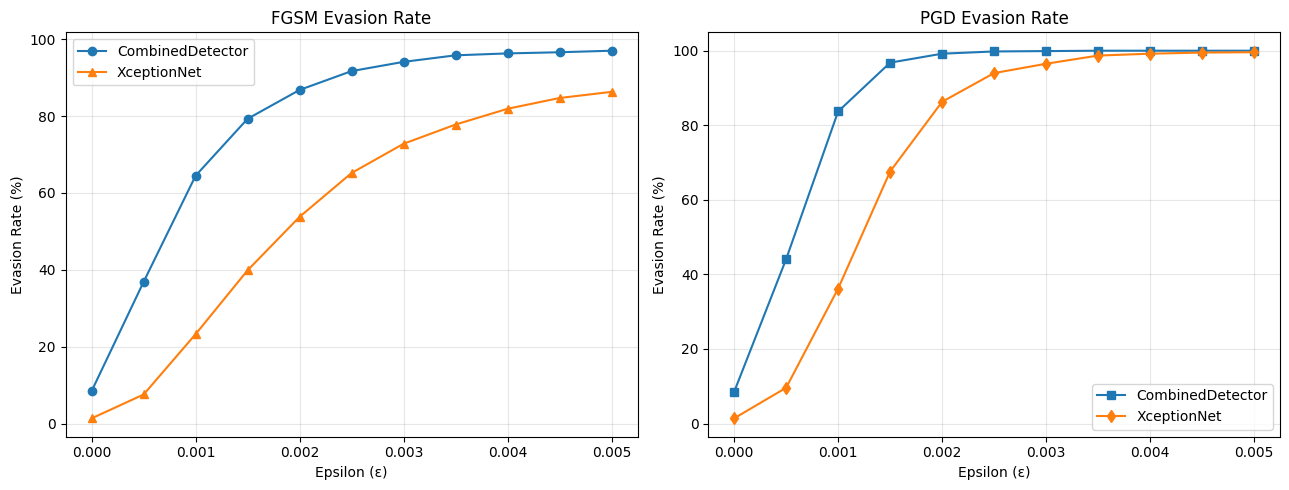

In [ ]:
import matplotlib.pyplot as plt

EPSILONS = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.0045, 0.005]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(EPSILONS, combined_fgsm_evasion, 'o-', label='CombinedDetector (split-aug)')
ax1.plot(EPSILONS, xception_fgsm_evasion, '^-', label='XceptionNet')
ax1.set_title('FGSM Evasion Rate')
ax1.set_xlabel('Epsilon (ε)')
ax1.set_ylabel('Evasion Rate (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(EPSILONS, combined_pgd_evasion, 's-', label='CombinedDetector (split-aug)')
ax2.plot(EPSILONS, xception_pgd_evasion, 'd-', label='XceptionNet')
ax2.set_title('PGD Evasion Rate')
ax2.set_xlabel('Epsilon (ε)')
ax2.set_ylabel('Evasion Rate (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig_whitebox_evasionnewdet.png', dpi=200)
plt.show()

#Defence section

Adversarial fine tuning

##Kept FGSM version

Fine-tunes the CombinedDetector using a 50/50 mixture of clean and FGSM-perturbed training samples.
BatchNorm stats are frozen while adversarial examples are generated, then the model is returned to training mode for optimisation

In [ ]:
def adversarial_training_dual(model, train_loader, optimizer, epsilon, num_epochs=15, scheduler=None):
    for epoch in range(num_epochs):
        running_loss = 0.0
        correct, total = 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            model.eval()  # freeze BatchNorm stats during attack generation
            adv_images = fgsm_attack_dual(model, images, labels, epsilon)

            model.train()  # switch back for the real training step
            mixed_images = torch.cat([images, adv_images], dim=0)
            mixed_labels = torch.cat([labels, labels], dim=0)

            optimizer.zero_grad()
            outputs = model(mixed_images, mixed_images)  # same image to both streams
            loss = criterion(outputs, mixed_labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == mixed_labels).sum().item()
            total += mixed_labels.size(0)

        if scheduler is not None:
            scheduler.step()

        print(f"Epoch {epoch+1}/{num_epochs} | Loss: {running_loss/len(train_loader):.4f} | Acc: {correct/total:.4f}")


##Configuration and Training
Initialises the robust model from the trained CombinedDetector checkpoint, then fine-tunes it for 15 epochs using FGSM adversarial training with ε = 0.001. The same differential learning rates used during CombinedDetector training are retained, with cosine annealing applied across the fine-tuning period.

In [ ]:
Robust_SplitAug_CombinedDetector = CombinedDetector().to(device) ## Creating a new CombinedDetector for adversarial fine-tuning
Robust_SplitAug_CombinedDetector.load_state_dict(combined_model.state_dict())  #Initialising it using the weights of the trained undefended CombinedDetector

num_epochs = 15
criterion = nn.CrossEntropyLoss()

optimizer_robust = optim.Adam([
    {'params': Robust_SplitAug_CombinedDetector.xception.parameters(), 'lr': 0.00001},  #same as previous training
    {'params': Robust_SplitAug_CombinedDetector.freq_branch.parameters(), 'lr': 0.0001},
    {'params': Robust_SplitAug_CombinedDetector.classifier.parameters(), 'lr': 0.0001}
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer_robust, T_max=num_epochs)

print("Training Robust_SplitAug_CombinedDetector (FGSM)...") ## adv fine-tuning using ep=0.001, low-magnitude perturbation effective during white-box eval
adversarial_training_dual(Robust_SplitAug_CombinedDetector, train_loader, optimizer_robust, epsilon=0.001, num_epochs=num_epochs, scheduler=scheduler)

torch.save(Robust_SplitAug_CombinedDetector.state_dict(), '/content/drive/MyDrive/robust_splitaug_combined.pth')
print("Saved.")

Training Robust_SplitAug_CombinedDetector (FGSM)...
Epoch 1/15 | Loss: 0.5956 | Acc: 0.6792
Epoch 2/15 | Loss: 0.5168 | Acc: 0.7331
Epoch 3/15 | Loss: 0.4726 | Acc: 0.7649
Epoch 4/15 | Loss: 0.4297 | Acc: 0.7893
Epoch 5/15 | Loss: 0.3925 | Acc: 0.8084
Epoch 6/15 | Loss: 0.3589 | Acc: 0.8297
Epoch 7/15 | Loss: 0.3374 | Acc: 0.8415
Epoch 8/15 | Loss: 0.3067 | Acc: 0.8605
Epoch 9/15 | Loss: 0.2819 | Acc: 0.8709
Epoch 10/15 | Loss: 0.2714 | Acc: 0.8770
Epoch 11/15 | Loss: 0.2634 | Acc: 0.8805
Epoch 12/15 | Loss: 0.2577 | Acc: 0.8838
Epoch 13/15 | Loss: 0.2476 | Acc: 0.8879
Epoch 14/15 | Loss: 0.2378 | Acc: 0.8943
Epoch 15/15 | Loss: 0.2433 | Acc: 0.8908
Saved.


##Clean test eval before attack
Evaluating defended CombinedDetector on the clean held-out test set.
Accuracy, AUC-ROC, F1 score and the confusion matrix are reported to assess how the adversarial fine-tuning affected standard classification performance in addition to robustness

In [ ]:
Robust_SplitAug_CombinedDetector.eval()

  ## Switch the defended model to evaluation mode
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = Robust_SplitAug_CombinedDetector(images, images)
        probs = torch.softmax(outputs, dim=1)[:, 1]   #fake F1 version calculated mathematically for report (0.9363)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())


acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
f1 = f1_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)
print(f"Test Accuracy: {acc*100:.2f}%")
print(f"AUC-ROC: {auc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Confusion Matrix:\n{cm}")

Test Accuracy: 93.62%
AUC-ROC: 0.9868
F1 Score: 0.9362
Confusion Matrix:
[[1125   80]
 [  73 1122]]


##Running same attack again/ Adversarial Robustness Evaluation After Fine-Tuning

In [ ]:
alpha = 0.0005
num_steps = 20

print("Robust CombinedDetector - FGSM")
robust_fgsm_evasion = evasion_rate_dual(Robust_SplitAug_CombinedDetector, test_loader, fgsm_attack_dual, EPSILONS)

print("\nRobust CombinedDetector - PGD")
robust_pgd_evasion = evasion_rate_dual(Robust_SplitAug_CombinedDetector, test_loader, pgd_attack_dual, EPSILONS, alpha=0.0005, num_steps=20)

Robust CombinedDetector - FGSM
  ε=0.0000 → Evasion rate: 6.6% (80/1205)
  ε=0.0005 → Evasion rate: 13.9% (168/1205)
  ε=0.0010 → Evasion rate: 25.4% (306/1205)
  ε=0.0015 → Evasion rate: 37.9% (457/1205)
  ε=0.0020 → Evasion rate: 48.0% (578/1205)
  ε=0.0025 → Evasion rate: 56.3% (679/1205)
  ε=0.0030 → Evasion rate: 63.5% (765/1205)
  ε=0.0035 → Evasion rate: 70.6% (851/1205)
  ε=0.0040 → Evasion rate: 75.6% (911/1205)
  ε=0.0045 → Evasion rate: 78.7% (948/1205)
  ε=0.0050 → Evasion rate: 81.2% (979/1205)

Robust CombinedDetector - PGD
  ε=0.0000 → Evasion rate: 6.6% (80/1205)
  ε=0.0005 → Evasion rate: 15.0% (181/1205)
  ε=0.0010 → Evasion rate: 31.7% (382/1205)
  ε=0.0015 → Evasion rate: 51.4% (619/1205)
  ε=0.0020 → Evasion rate: 70.1% (845/1205)
  ε=0.0025 → Evasion rate: 82.6% (995/1205)
  ε=0.0030 → Evasion rate: 89.3% (1076/1205)
  ε=0.0035 → Evasion rate: 93.0% (1121/1205)
  ε=0.0040 → Evasion rate: 95.5% (1151/1205)
  ε=0.0045 → Evasion rate: 96.9% (1168/1205)
  ε=0.0050 → E

## Plotting the Effect of Adversarial Fine-Tuning on Evasion Rate
Final recorded evasion rates used for the report figure

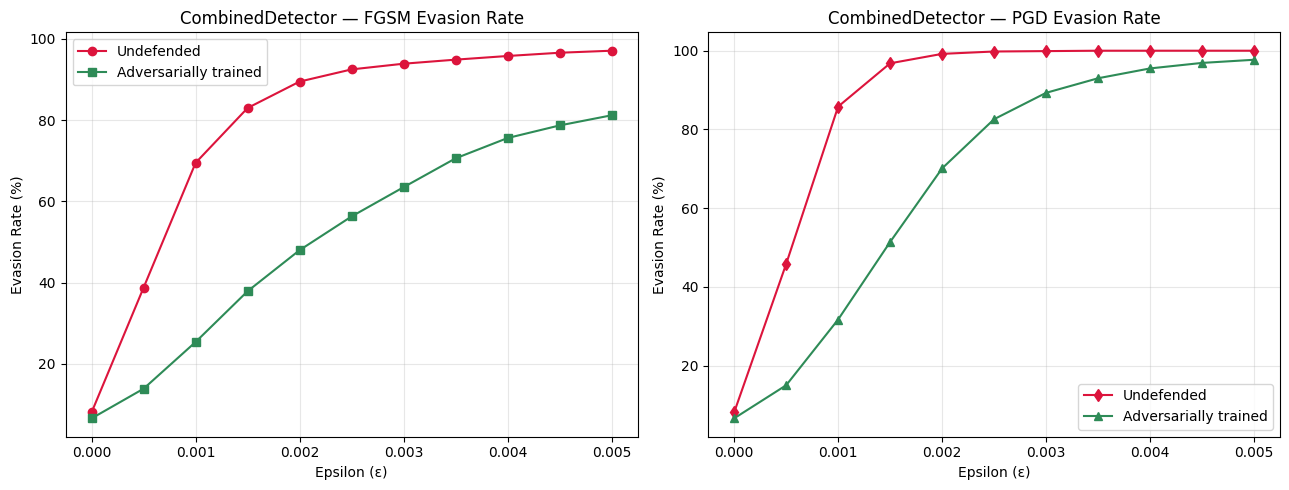

In [ ]:
import matplotlib.pyplot as plt

EPSILONS = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.0045, 0.005]

# undefended CombinedDetector
combined_fgsm_evasion = [8.1, 38.8, 69.5, 83.0, 89.5, 92.5, 93.9, 94.9, 95.8, 96.6, 97.1]
combined_pgd_evasion  = [8.1, 45.8, 85.8, 96.8, 99.2, 99.8, 99.9, 100.0, 100.0, 100.0, 100.0]

# Robust-CombinedDetector (adversarially fine-tuned)
robust_fgsm_evasion = [6.6, 13.9, 25.4, 37.9, 48.0, 56.3, 63.5, 70.6, 75.6, 78.7, 81.2]
robust_pgd_evasion  = [6.6, 15.0, 31.7, 51.4, 70.1, 82.6, 89.3, 93.0, 95.5, 96.9, 97.7]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(EPSILONS, combined_fgsm_evasion, 'o-', color='crimson', label='Undefended')
ax1.plot(EPSILONS, robust_fgsm_evasion, 's-', color='seagreen', label='Adversarially trained')
ax1.set_title('CombinedDetector — FGSM Evasion Rate')
ax1.set_xlabel('Epsilon (ε)')
ax1.set_ylabel('Evasion Rate (%)')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(EPSILONS, combined_pgd_evasion, 'd-', color='crimson', label='Undefended')
ax2.plot(EPSILONS, robust_pgd_evasion, '^-', color='seagreen', label='Adversarially trained')
ax2.set_title('CombinedDetector — PGD Evasion Rate')
ax2.set_xlabel('Epsilon (ε)')
ax2.set_ylabel('Evasion Rate (%)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig_combineddetector_advtraining_defencenewdet.png', dpi=200)
plt.show()

#Low-pass filter defence





Loading undefended and defended CombinedDetectors

In [ ]:
combined_model = CombinedDetector().cuda()
combined_model.load_state_dict(torch.load('/content/drive/MyDrive/best_model_combinedwimpfftsplitaug.pth'))
combined_model.eval()
print("Undefended CombinedDetector loaded")

Robust_SplitAug_CombinedDetector = CombinedDetector().cuda()
Robust_SplitAug_CombinedDetector.load_state_dict(torch.load('/content/drive/MyDrive/robust_splitaug_combined.pth'))
Robust_SplitAug_CombinedDetector.eval()
print("Robust CombinedDetector loaded")

Undefended CombinedDetector loaded
Robust CombinedDetector loaded


## Gaussian Low-Pass Filter
Defining the preprocessing defence applied to adversarial images before classification. A Gaussian blur with a 3×3 kernel and sigma = 0.5 is used to suppress high-frequency image components that may contain adversarial perturbations. (attempted 5x5 and 1.0 first but was too strong)

In [ ]:
import torchvision.transforms.functional as TF

def gaussian_low_pass(images, kernel_size=3, sigma=0.5):
    return TF.gaussian_blur(
        images,
        kernel_size=[kernel_size, kernel_size],
        sigma=[sigma, sigma]
    )

##CLEAN ACCURACY WITH LOW-PASS FILTER
Evaluates the adversarially trained CombinedDetector on clean test images after Gaussian low-pass filtering

In [ ]:
def evaluate_clean_with_lowpass(
    model,
    test_loader,
    kernel_size=3,
    sigma=0.5
):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            filtered_images = gaussian_low_pass(
                images,
                kernel_size=kernel_size,
                sigma=sigma
            )

            outputs = model(filtered_images, filtered_images)
            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    print(
        f"Clean accuracy w low-pass filter "
        f"(kernel={kernel_size}, sigma={sigma}): "
        f"{accuracy:.2f}%"
    )

    return accuracy

##Adversarial Evasion Evaluation with Low-Pass Filtering

In [ ]:
def evasion_rate_with_lowpass(
    model,
    test_loader,
    attack_fn,
    epsilons,
    kernel_size=3,
    sigma=0.5,
    **attack_kwargs
):
    model.eval()

    evasion_rates = []

    for eps in epsilons:

        fooled = 0
        total_fake = 0

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            fake_mask = (labels == 0)

            if fake_mask.sum() == 0:
                continue

            fake_images = images[fake_mask]
            fake_labels = labels[fake_mask]

            adv_images = attack_fn(
                model,
                fake_images,
                fake_labels,
                eps,
                **attack_kwargs
            )

            filtered_adv = gaussian_low_pass(
                adv_images,
                kernel_size=kernel_size,
                sigma=sigma
            )

            with torch.no_grad():
                outputs = model(filtered_adv, filtered_adv)
                predicted = outputs.argmax(dim=1)

            fooled += (predicted == 1).sum().item()
            total_fake += fake_labels.size(0)

        rate = 100 * fooled / total_fake
        evasion_rates.append(rate)

        print(
            f"ε={eps:.4f} → "
            f"Low-pass evasion rate: "
            f"{rate:.1f}% ({fooled}/{total_fake})"
        )

    return evasion_rates

## Low-pass filter as defence (Alone)

In [ ]:
print("=== Low-pass alone (undefended CombinedDetector) ===")
undefended_lowpass_clean_acc = evaluate_clean_with_lowpass(
    combined_model,
    test_loader,
    kernel_size=3,
    sigma=0.5
)

print("\n=== FGSM + Low-pass (undefended CombinedDetector) ===")
undefended_fgsm_lowpass = evasion_rate_with_lowpass(
    combined_model,
    test_loader,
    fgsm_attack_dual,
    EPSILONS,
    kernel_size=3,
    sigma=0.5
)

=== Low-pass alone (undefended CombinedDetector) ===
Clean accuracy w low-pass filter (kernel=3, sigma=0.5): 90.33%

=== FGSM + Low-pass (undefended CombinedDetector) ===
ε=0.0000 → Low-pass evasion rate: 4.5% (54/1205)
ε=0.0005 → Low-pass evasion rate: 17.8% (214/1205)
ε=0.0010 → Low-pass evasion rate: 39.5% (476/1205)
ε=0.0015 → Low-pass evasion rate: 59.2% (713/1205)
ε=0.0020 → Low-pass evasion rate: 72.1% (869/1205)
ε=0.0025 → Low-pass evasion rate: 81.5% (982/1205)
ε=0.0030 → Low-pass evasion rate: 86.3% (1040/1205)
ε=0.0035 → Low-pass evasion rate: 89.4% (1077/1205)
ε=0.0040 → Low-pass evasion rate: 92.0% (1108/1205)
ε=0.0045 → Low-pass evasion rate: 92.9% (1119/1205)
ε=0.0050 → Low-pass evasion rate: 93.8% (1130/1205)


##Clean accuracy with lowpass on robust detector , then FGSM

In [ ]:
KERNEL_SIZE = 3
SIGMA = 0.5

print("=== CLEAN LOW-PASS TEST ===")

lowpass_clean_acc = evaluate_clean_with_lowpass(
    Robust_SplitAug_CombinedDetector,
    test_loader,
    kernel_size=KERNEL_SIZE,
    sigma=SIGMA
)

=== CLEAN LOW-PASS TEST ===
Clean accuracy w low-pass filter (kernel=3, sigma=0.5): 89.83%


In [ ]:
print("\n=== FGSM + LOW-PASS ===")

robust_fgsm_lowpass = evasion_rate_with_lowpass(
    Robust_SplitAug_CombinedDetector,
    test_loader,
    fgsm_attack_dual,
    EPSILONS,
    kernel_size=KERNEL_SIZE,
    sigma=SIGMA
)



=== FGSM + LOW-PASS ===
ε=0.0000 → Low-pass evasion rate: 3.0% (36/1205)
ε=0.0005 → Low-pass evasion rate: 5.5% (66/1205)
ε=0.0010 → Low-pass evasion rate: 10.4% (125/1205)
ε=0.0015 → Low-pass evasion rate: 16.3% (196/1205)
ε=0.0020 → Low-pass evasion rate: 22.7% (273/1205)
ε=0.0025 → Low-pass evasion rate: 29.7% (358/1205)
ε=0.0030 → Low-pass evasion rate: 36.3% (438/1205)
ε=0.0035 → Low-pass evasion rate: 43.1% (519/1205)
ε=0.0040 → Low-pass evasion rate: 49.2% (593/1205)
ε=0.0045 → Low-pass evasion rate: 55.1% (664/1205)
ε=0.0050 → Low-pass evasion rate: 59.7% (719/1205)


##Detailed Clean Evaluation with Low-Pass Filtering
Evaluates the adversarially fine-tuned CombinedDetector on low-pass filtered clean test images using overall accuracy, a confusion matrix and per-class classification metrics. This helped to identify the class-specific bias introduced by the preprocessing defence.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Robust_SplitAug_CombinedDetector.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        filtered_images = gaussian_low_pass(
            images,
            kernel_size=3,
            sigma=0.5
        )

        outputs = Robust_SplitAug_CombinedDetector(filtered_images, filtered_images)
        preds = outputs.argmax(dim=1)  #both scores shown here no change needed

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)

print(f"Low-pass clean accuracy: {acc*100:.2f}%")
print(f"Confusion Matrix:\n{cm}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=["Fake", "Real"]
    )
)

Low-pass clean accuracy: 89.83%
Confusion Matrix:
[[1169   36]
 [ 208  987]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.85      0.97      0.91      1205
        Real       0.96      0.83      0.89      1195

    accuracy                           0.90      2400
   macro avg       0.91      0.90      0.90      2400
weighted avg       0.91      0.90      0.90      2400



## Visual FGSM Defence Comparison

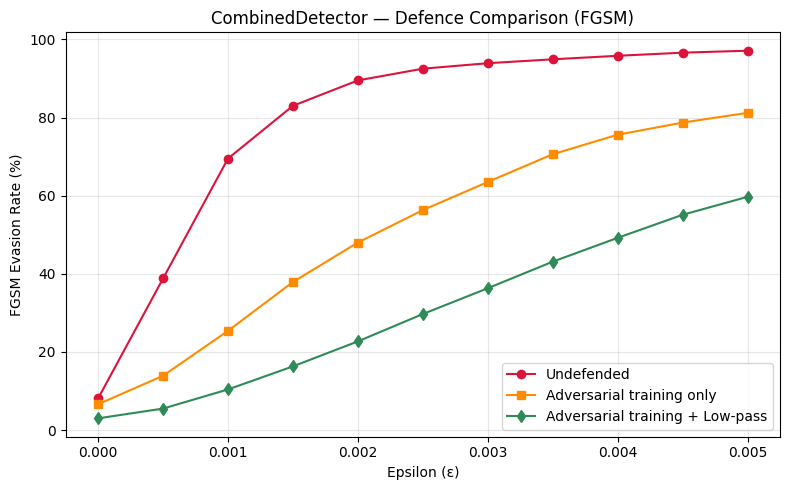

In [ ]:
import matplotlib.pyplot as plt

EPSILONS = [0.0, 0.0005, 0.001, 0.0015, 0.002, 0.0025, 0.003, 0.0035, 0.004, 0.0045, 0.005]

combined_fgsm_evasion = [8.1, 38.8, 69.5, 83.0, 89.5, 92.5, 93.9, 94.9, 95.8, 96.6, 97.1]
robust_fgsm_evasion   = [6.6, 13.9, 25.4, 37.9, 48.0, 56.3, 63.5, 70.6, 75.6, 78.7, 81.2]
robust_fgsm_lowpass   = [3.0,5.5,10.4,16.3,22.7,29.7,36.3,43.1,49.2,55.1,59.7]

plt.figure(figsize=(8, 5))
plt.plot(EPSILONS, combined_fgsm_evasion, 'o-', color='crimson', label='Undefended')
plt.plot(EPSILONS, robust_fgsm_evasion, 's-', color='darkorange', label='Adversarial training only')
plt.plot(EPSILONS, robust_fgsm_lowpass, 'd-', color='seagreen', label='Adversarial training + Low-pass')
plt.xlabel('Epsilon (ε)')
plt.ylabel('FGSM Evasion Rate (%)')
plt.title('CombinedDetector — Defence Comparison (FGSM)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fig_lowpass_defence_fgsm_newdet.png', dpi=200)
plt.show()

##Qualitative Adversarial Example Comparison

Visualises a successful adversarial example against the CombinedDetector.
The figure compares the original fake image, the amplified perturbation, the adversarial image evaluated by the undefended model, and the same adversarial image evaluated by the defended model. Showing how adversarial fine-tuning affects the detector’s prediction.

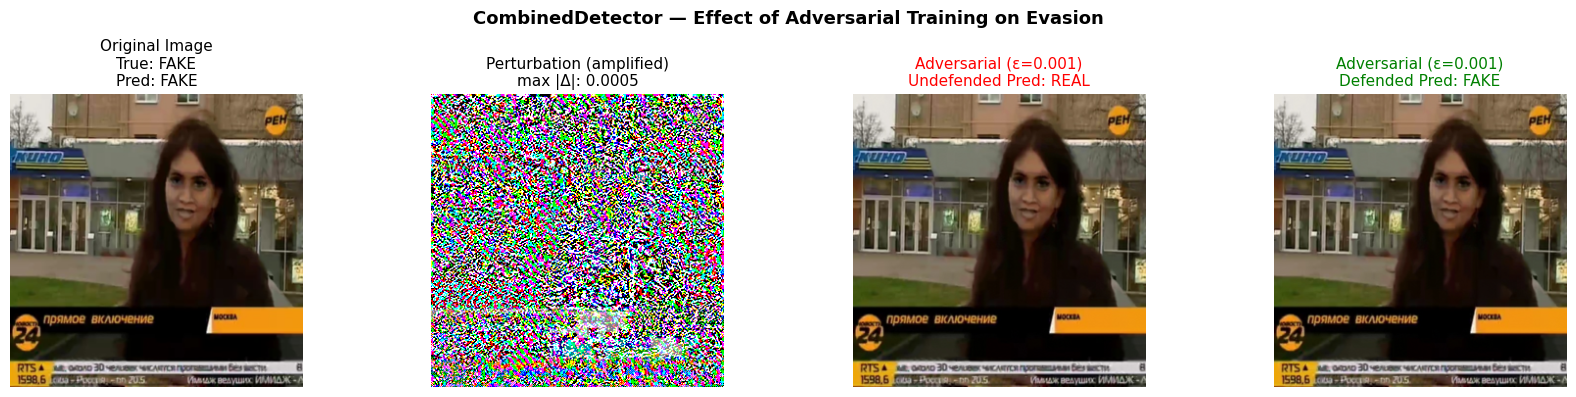

In [ ]:
def unnormalize(img_tensor):
    img = img_tensor.squeeze().cpu().permute(1, 2, 0).numpy()
    img = (img * 0.5) + 0.5
    return np.clip(img, 0, 1)

clean_np = unnormalize(clean_img)
adv_undefended_np = unnormalize(adv_img_undefended)
adv_defended_np = unnormalize(adv_img_defended)

perturb_np = adv_undefended_np - clean_np
perturb_vis = (perturb_np - perturb_np.min()) / (perturb_np.max() - perturb_np.min() + 1e-8)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))

axes[0].imshow(clean_np)
axes[0].set_title(f'Original Image\nTrue: FAKE\nPred: {"REAL" if pred_clean==1 else "FAKE"}', fontsize=11)
axes[0].axis('off')

axes[1].imshow(perturb_vis, cmap='RdBu')
axes[1].set_title(f'Perturbation (amplified)\nmax |Δ|: {np.abs(perturb_np).max():.4f}', fontsize=11)
axes[1].axis('off')

axes[2].imshow(adv_undefended_np)
axes[2].set_title(f'Adversarial (ε={epsilon})\nUndefended Pred: {"REAL" if pred_undefended==1 else "FAKE"}', fontsize=11,
                   color='red' if pred_undefended == 1 else 'green')
axes[2].axis('off')

axes[3].imshow(adv_defended_np)
axes[3].set_title(f'Adversarial (ε={epsilon})\nDefended Pred: {"REAL" if pred_defended==1 else "FAKE"}', fontsize=11,
                   color='red' if pred_defended == 1 else 'green')
axes[3].axis('off')

plt.suptitle('CombinedDetector — Effect of Adversarial Training on Evasion', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/qualitative_defense_comparisonfinal.png', dpi=150, bbox_inches='tight')
plt.show()

## Simply a visual needed for final report

Showing the CombinedDetector classifying a sample of images, as well as its confidence

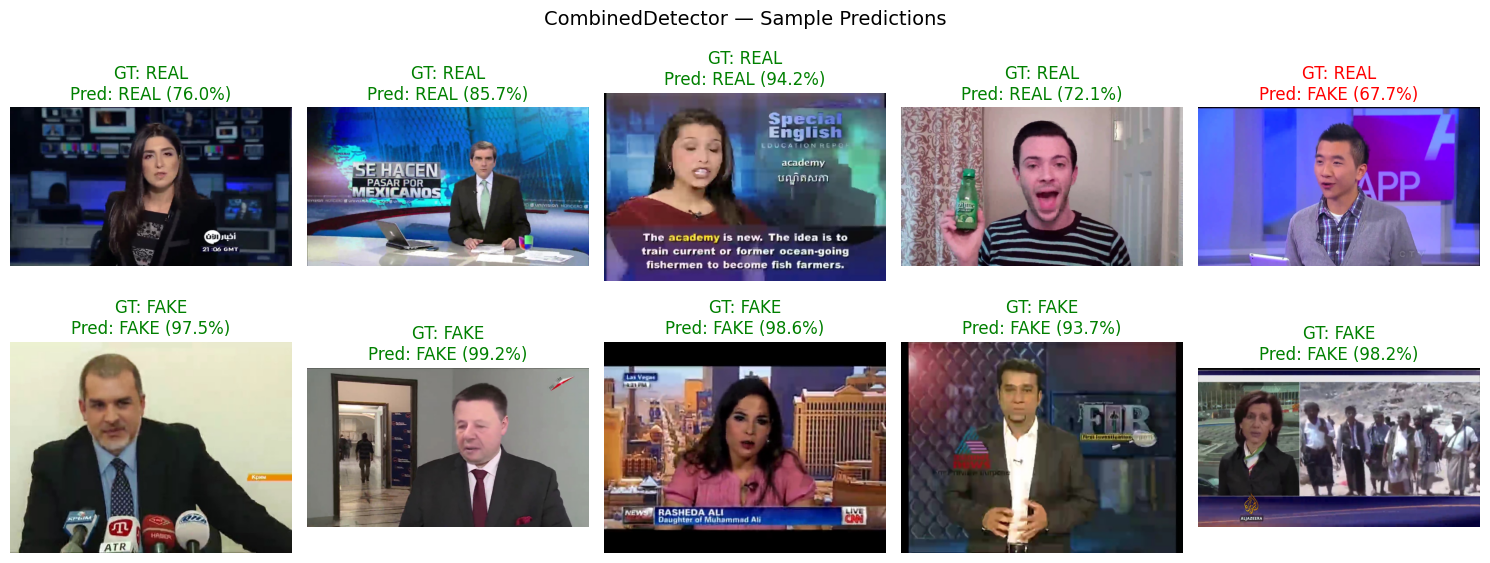

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

combined_model.eval()

test_dir_real = '/content/data_combined_8k/real'
test_dir_fake = '/content/data_combined_8k/fake'

real_images = random.sample(os.listdir(test_dir_real), 5)
fake_images = random.sample(os.listdir(test_dir_fake), 5)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, fname in enumerate(real_images):
    img_path = os.path.join(test_dir_real, fname)
    img = Image.open(img_path).convert('RGB')
    tensor = test_transform(img).unsqueeze(0).cuda()

    with torch.no_grad():
        output = combined_model(tensor, tensor)
        prob = torch.softmax(output, dim=1)[0]
        pred = 'REAL' if output.argmax() == 1 else 'FAKE'
        conf = prob.max().item() * 100

    axes[0, i].imshow(img)
    axes[0, i].set_title(f'GT: REAL\nPred: {pred} ({conf:.1f}%)',
                          color='green' if pred == 'REAL' else 'red')
    axes[0, i].axis('off')

for i, fname in enumerate(fake_images):
    img_path = os.path.join(test_dir_fake, fname)
    img = Image.open(img_path).convert('RGB')
    tensor = test_transform(img).unsqueeze(0).cuda()

    with torch.no_grad():
        output = combined_model(tensor, tensor)
        prob = torch.softmax(output, dim=1)[0]
        pred = 'REAL' if output.argmax() == 1 else 'FAKE'
        conf = prob.max().item() * 100

    axes[1, i].imshow(img)
    axes[1, i].set_title(f'GT: FAKE\nPred: {pred} ({conf:.1f}%)',
                          color='green' if pred == 'FAKE' else 'red')
    axes[1, i].axis('off')

plt.suptitle('CombinedDetector — Sample Predictions', fontsize=14)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/sample_predictionscombinedwimpfft.png', dpi=150)
plt.show()

##Frequency Branch Ablation Test
producing an approximate indication of how much the frequency stream contributes to the final classifier

In [ ]:
correct_baseline = 0
total_samples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.cuda(), labels.cuda()
        outputs = combined_model(images, images)
        predictions = torch.argmax(outputs, dim=1)
        correct_baseline += (predictions == labels).sum().item()
        total_samples += labels.size(0)

baseline_acc = (correct_baseline / total_samples) * 100
print(f"Baseline Accuracy (Both Branches Active): {baseline_acc:.2f}%")

def zero_fft_hook(module, input, output): #using hook to zero fft branch
    output.zero_()
    return output

hook_handle = combined_model.freq_branch.register_forward_hook(zero_fft_hook) #Register the hook

correct_ablation = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.cuda(), labels.cuda()
        outputs = combined_model(images, images)
        predictions = torch.argmax(outputs, dim=1)
        correct_ablation += (predictions == labels).sum().item()

ablation_acc = (correct_ablation / total_samples) * 100
print(f"Ablation Accuracy (FFT Branch Zeroed Out): {ablation_acc:.2f}%")

fft_contribution = baseline_acc - ablation_acc
print(f"Net FFT Branch Contribution: {fft_contribution:.2f}%")

hook_handle.remove() #Remove hook after

Baseline Accuracy (Both Branches Active): 92.75%
Ablation Accuracy (FFT Branch Zeroed Out): 92.71%
Net FFT Branch Contribution: 0.04%
